<a href="https://colab.research.google.com/github/nitha604/news-article-categorisation/blob/main/02_data_expolaration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install required libraries
# Run this once — it installs quietly (that's what -q does)
!pip install wordcloud matplotlib seaborn pandas -q

In [2]:
import pandas as pd

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/news_project/raw_data.csv')

# Quick look at what we've got
print(f" Dataset loaded successfully!")
print(f" Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("\n First 3 rows:")
df.head(3)


Mounted at /content/drive
 Dataset loaded successfully!
 Shape: 2040 rows × 2 columns

 First 3 rows:


,text,category
0,Barrera outslugs Morales for title Somehow Mar...,Sports
1,Ajax finally comes to terms with Trabelsi Amst...,Sports
2,Steelers' Burress to Miss Game With Jets (AP) ...,Sports


/tmp/ipykernel_1753/294786474.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


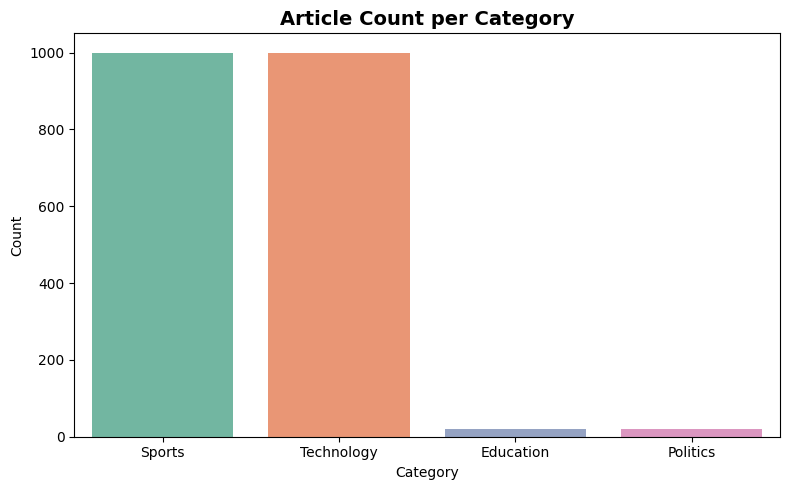


 Article count per category:
category
Sports        1000
Technology    1000
Education       20
Politics        20
Name: count, dtype: int64

 Max/Min ratio: 50.00
 Dataset is imbalanced — consider balancing techniques later.


In [3]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create the plots folder if it doesn't exist
os.makedirs('/content/drive/MyDrive/news_project/plots', exist_ok=True)

# Plot class distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='category',
    palette='Set2',
    order=df['category'].value_counts().index
)
plt.title('Article Count per Category', fontsize=14, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Count')
plt.tight_layout()

# Save the plot
plt.savefig('/content/drive/MyDrive/news_project/plots/class_distribution.png', dpi=150)
plt.show()

print("\n Article count per category:")
print(df['category'].value_counts())

# Check if balanced
counts = df['category'].value_counts()
ratio = counts.max() / counts.min()
print(f"\n Max/Min ratio: {ratio:.2f}")
if ratio < 1.5:
    print(" Dataset looks fairly balanced!")
else:
    print(" Dataset is imbalanced — consider balancing techniques later.")


📏 Word count statistics per category:
             count  mean   std   min   25%   50%   75%    max
category                                                     
Education     20.0   9.7   1.3   6.0   9.0  10.0  11.0   11.0
Politics      20.0   9.6   1.4   7.0   9.0   9.5  10.0   12.0
Sports      1000.0  37.9   9.2  17.0  32.0  37.0  43.0   88.0
Technology  1000.0  37.4  12.5  10.0  30.0  36.0  42.0  129.0


/tmp/ipykernel_1753/1678173373.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


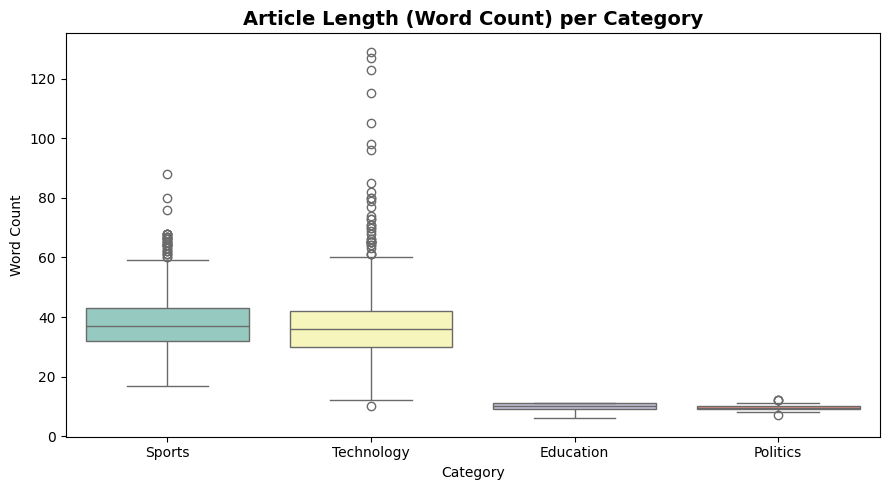


 Overall word count stats:
count    2040.0
mean       37.1
std        11.5
min         6.0
25%        30.0
50%        36.0
75%        42.0
max       129.0
Name: word_count, dtype: float64


In [4]:
# Add a word_count column
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

print("📏 Word count statistics per category:")
print(df.groupby('category')['word_count'].describe().round(1))

# Box plot of word count per category
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x='category',
    y='word_count',
    palette='Set3',
    order=df['category'].value_counts().index
)
plt.title('Article Length (Word Count) per Category', fontsize=14, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Word Count')
plt.tight_layout()

# Save the plot
plt.savefig('/content/drive/MyDrive/news_project/plots/article_lengths.png', dpi=150)
plt.show()

print(f"\n Overall word count stats:")
print(df['word_count'].describe().round(1))


In [5]:
print("=" * 40)
print(" Missing Values Check")
print("=" * 40)
print(df.isnull().sum())

print("\n" + "=" * 40)
print(" Duplicate Rows Check")
print("=" * 40)
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

# Drop duplicates and null values
df.drop_duplicates(inplace=True)
df.dropna(subset=['text', 'category'], inplace=True)
df.reset_index(drop=True, inplace=True)

print("\n" + "=" * 40)
print(" After Cleaning")
print("=" * 40)
print(f"New shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("No missing values or duplicates remain! ")


 Missing Values Check
text          0
category      0
word_count    0
dtype: int64

 Duplicate Rows Check
Number of duplicate rows: 0

 After Cleaning
New shape: 2040 rows × 3 columns
No missing values or duplicates remain! 


In [6]:
from sklearn.feature_extraction.text import CountVectorizer

print(" Top 20 Most Frequent Words per Category (Raw — before stopword removal)\n")
print("=" * 60)

categories = df['category'].unique()

for cat in sorted(categories):
    # Get all text for this category
    cat_texts = df[df['category'] == cat]['text'].astype(str).tolist()

    # Use CountVectorizer to find top words
    cv = CountVectorizer(max_features=20)
    cv.fit(cat_texts)
    word_counts = cv.transform(cat_texts).toarray().sum(axis=0)
    word_freq = sorted(
        zip(cv.get_feature_names_out(), word_counts),
        key=lambda x: x[1],
        reverse=True
    )

    # Print as a simple table
    print(f"\n  Category: {cat.upper()}")
    print(f"{'Rank':<6} {'Word':<20} {'Count':<10}")
    print("-" * 36)
    for rank, (word, count) in enumerate(word_freq, start=1):
        print(f"{rank:<6} {word:<20} {count:<10}")

print("\n" + "=" * 60)
print(" Note: Stopwords like 'the', 'is', 'in' are expected to appear frequently.")
print("   We'll remove them in Notebook 3 — Preprocessing!")


 Top 20 Most Frequent Words per Category (Raw — before stopword removal)


  Category: EDUCATION
Rank   Word                 Count     
------------------------------------
1      in                   7         
2      to                   7         
3      for                  5         
4      2024                 3         
5      announces            3         
6      class                3         
7      from                 3         
8      india                3         
9      schools              3         
10     students             3         
11     10                   2         
12     by                   2         
13     crore                2         
14     exam                 2         
15     introduces           2         
16     learning             2         
17     of                   2         
18     results              2         
19     university           2         
20     year                 2         

  Category: POLITICS
Rank   Word              

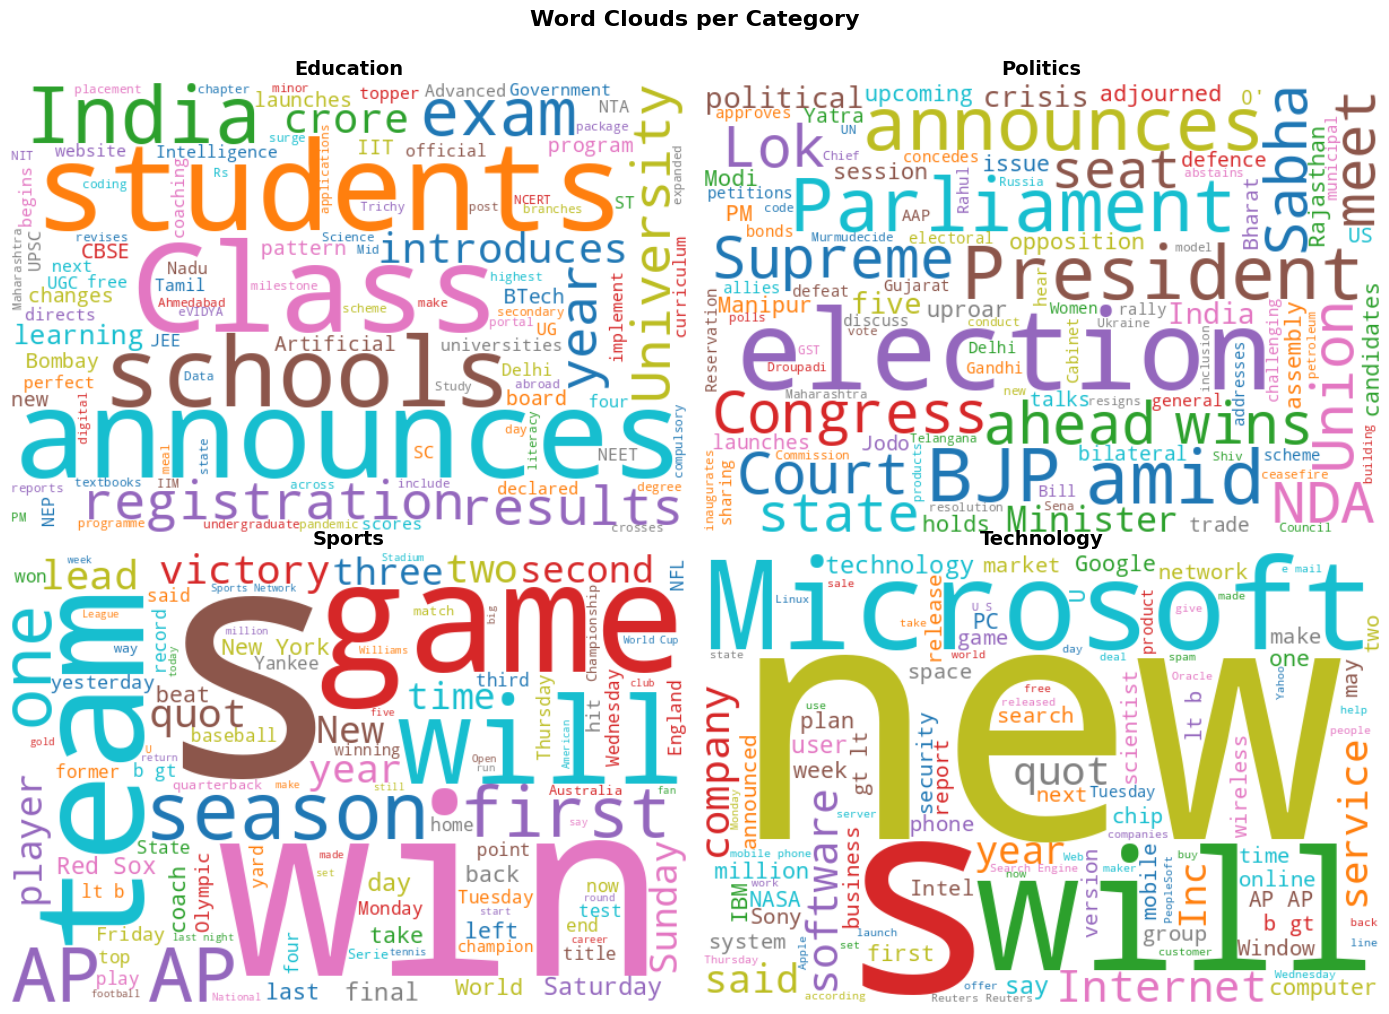

 Word clouds saved to Google Drive!


In [7]:
from wordcloud import WordCloud

# Get unique categories (up to 4)
unique_cats = sorted(df['category'].unique())[:4]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, cat in zip(axes.flatten(), unique_cats):
    # Combine all text for this category
    text = ' '.join(df[df['category'] == cat]['text'].astype(str))

    # Generate word cloud
    wc = WordCloud(
        width=600,
        height=400,
        background_color='white',
        max_words=100,
        colormap='tab10'
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(cat, fontsize=14, fontweight='bold')
    ax.axis('off')

plt.suptitle('Word Clouds per Category', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()

# Save the figure
plt.savefig('/content/drive/MyDrive/news_project/plots/wordclouds.png', dpi=150, bbox_inches='tight')
plt.show()

print(" Word clouds saved to Google Drive!")


In [8]:
import pandas as pd

# Build the summary table
summary_data = []

for cat in sorted(df['category'].unique()):
    cat_df = df[df['category'] == cat]
    summary_data.append({
        'Category': cat,
        'Count': len(cat_df),
        'Avg Words': round(cat_df['word_count'].mean(), 1),
        'Min Words': int(cat_df['word_count'].min()),
        'Max Words': int(cat_df['word_count'].max())
    })

# Add a total row
summary_data.append({
    'Category': ' TOTAL',
    'Count': len(df),
    'Avg Words': round(df['word_count'].mean(), 1),
    'Min Words': int(df['word_count'].min()),
    'Max Words': int(df['word_count'].max())
})

summary_df = pd.DataFrame(summary_data)

print(" Dataset Summary Table")
print("=" * 55)
print(summary_df.to_string(index=False))
print("=" * 55)

# Also display it nicely as a styled DataFrame
summary_df.style.set_caption("News Article Dataset Summary").hide(axis='index')


 Dataset Summary Table
  Category  Count  Avg Words  Min Words  Max Words
 Education     20        9.7          6         11
  Politics     20        9.6          7         12
    Sports   1000       37.9         17         88
Technology   1000       37.4         10        129
     TOTAL   2040       37.1          6        129


Category,Count,Avg Words,Min Words,Max Words
Education,20,9.700000,6,11
Politics,20,9.600000,7,12
Sports,1000,37.900000,17,88
Technology,1000,37.400000,10,129
TOTAL,2040,37.100000,6,129
